# MagicBrush Dataset Exploration

Quick exploration of the MagicBrush instruction-guided editing dataset.

## Dataset Overview & Schema

- **Source Used for Analysis:** Hugging Face [`osunlp/MagicBrush`](https://huggingface.co/datasets/osunlp/MagicBrush) (streaming `dev` split)
- **Where to Get Full Dataset Later:** Hugging Face repo [https://huggingface.co/datasets/osunlp/MagicBrush](https://huggingface.co/datasets/osunlp/MagicBrush) and GitHub [https://github.com/OSU-NLP-Group/MagicBrush](https://github.com/OSU-NLP-Group/MagicBrush)
- **Full Dataset Size:** ~10.5 GB compressed (~10,388 editing pairs with source image, mask, instruction, target image)
- **Use in Project:** Ground-truth benchmark for inpainting & object removal evaluation (comparing output vs `target_img`)

### Dataset Schema
| Column | Type | Description |
| :--- | :--- | :--- |
| `img_id` | `str` / `int` | Unique base image identifier. |
| `turn_index` | `int` | Turn number in the multi-turn editing sequence (1 for single edit). |
| `source_img` | `PIL.Image` | Input image before editing (RGB). |
| `mask_img` | `PIL.Image` | Binary / transparency mask indicating the modified region. |
| `instruction` | `str` | Text prompt describing the edit (e.g. "remove the dog"). |
| `target_img` | `PIL.Image` | Ground-truth image after editing (RGB). |


### 1. Load dataset samples (streaming mode)


In [1]:
from datasets import load_dataset

# Stream dev split of MagicBrush (instruction-guided image editing)
ds_stream = load_dataset("osunlp/MagicBrush", streaming=True, split="dev")
sample = list(ds_stream.take(50))


README.md:   0%|          | 0.00/3.85k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

### 2. Inspect DataFrame schema


In [8]:
import pandas as pd

# Convert samples into DataFrame (source image, mask, text instruction, target image)
df = pd.DataFrame(sample)
df


,img_id,turn_index,source_img,mask_img,instruction,target_img
0,140513,1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,edit some mountains in the background,<PIL.PngImagePlugin.PngImageFile image mode=RG...
1,140513,2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,put the zebras next to a river,<PIL.PngImagePlugin.PngImageFile image mode=RG...
2,319096,1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,Make the piece of paper hanging on the wall a ...,<PIL.PngImagePlugin.PngImageFile image mode=RG...
3,319096,2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,put an Easter basket on the desk,<PIL.PngImagePlugin.PngImageFile image mode=RG...
4,393224,1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,What if the man was bald,<PIL.PngImagePlugin.PngImageFile image mode=RG...
5,393224,2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,what if he had a angry mouth?,<PIL.PngImagePlugin.PngImageFile image mode=RG...
6,122896,1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,Have there be a dolphin jumping out of the water,<PIL.PngImagePlugin.PngImageFile image mode=RG...
7,415314,1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,replace the baseball bat for a laser sword,<PIL.PngImagePlugin.PngImageFile image mode=RG...
8,415314,2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,switch to a robot wearing armor,<PIL.PngImagePlugin.PngImageFile image mode=RG...
9,75065,1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,<PIL.PngImagePlugin.PngImageFile image mode=RG...,make the cow smile,<PIL.PngImagePlugin.PngImageFile image mode=RG...


### 3. Display source image


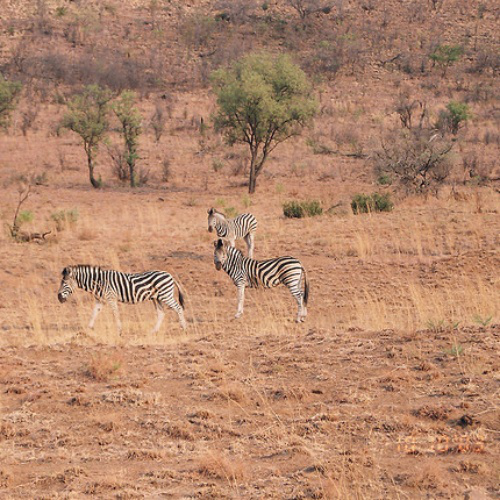

In [9]:
# Display original source image
df["source_img"].iloc[0]


### 4. Display editing mask


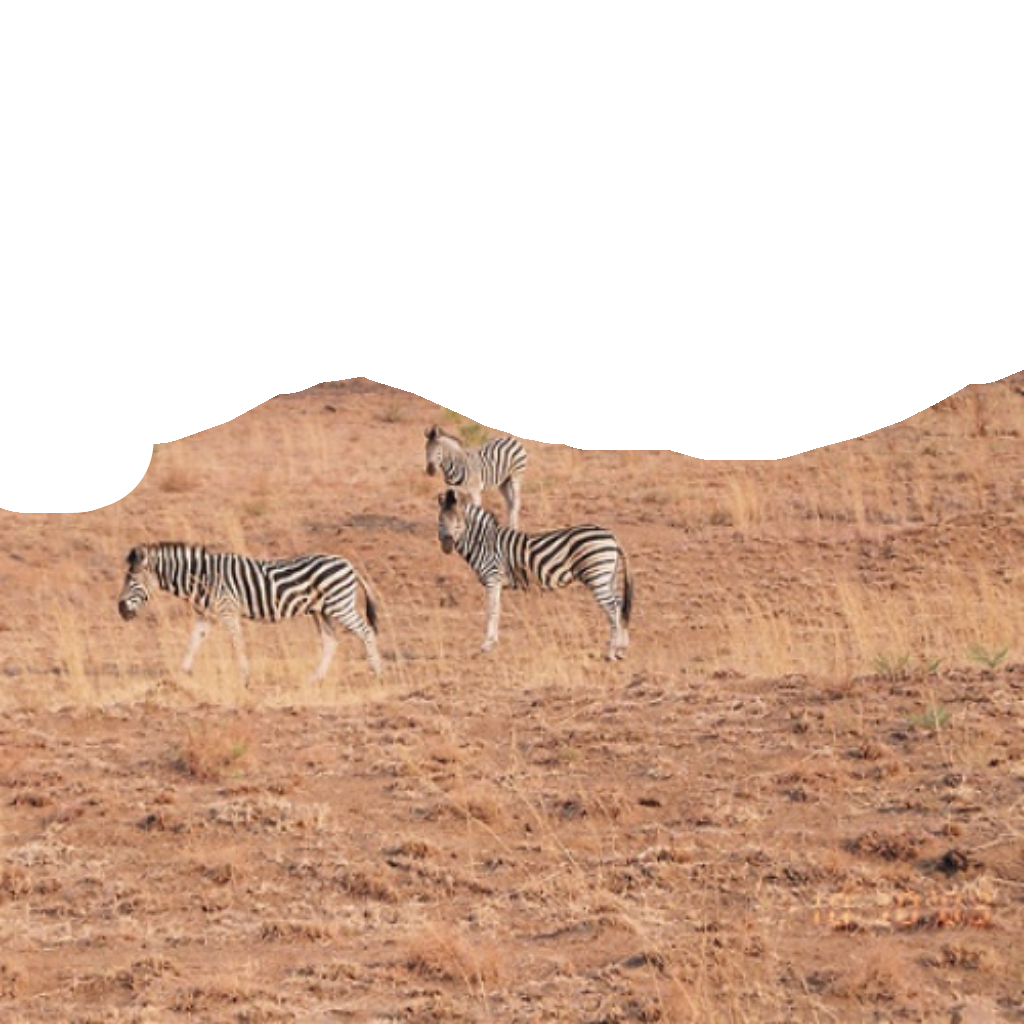

In [11]:
# Display editing region mask
df["mask_img"].iloc[0]


### 5. Display target edited image


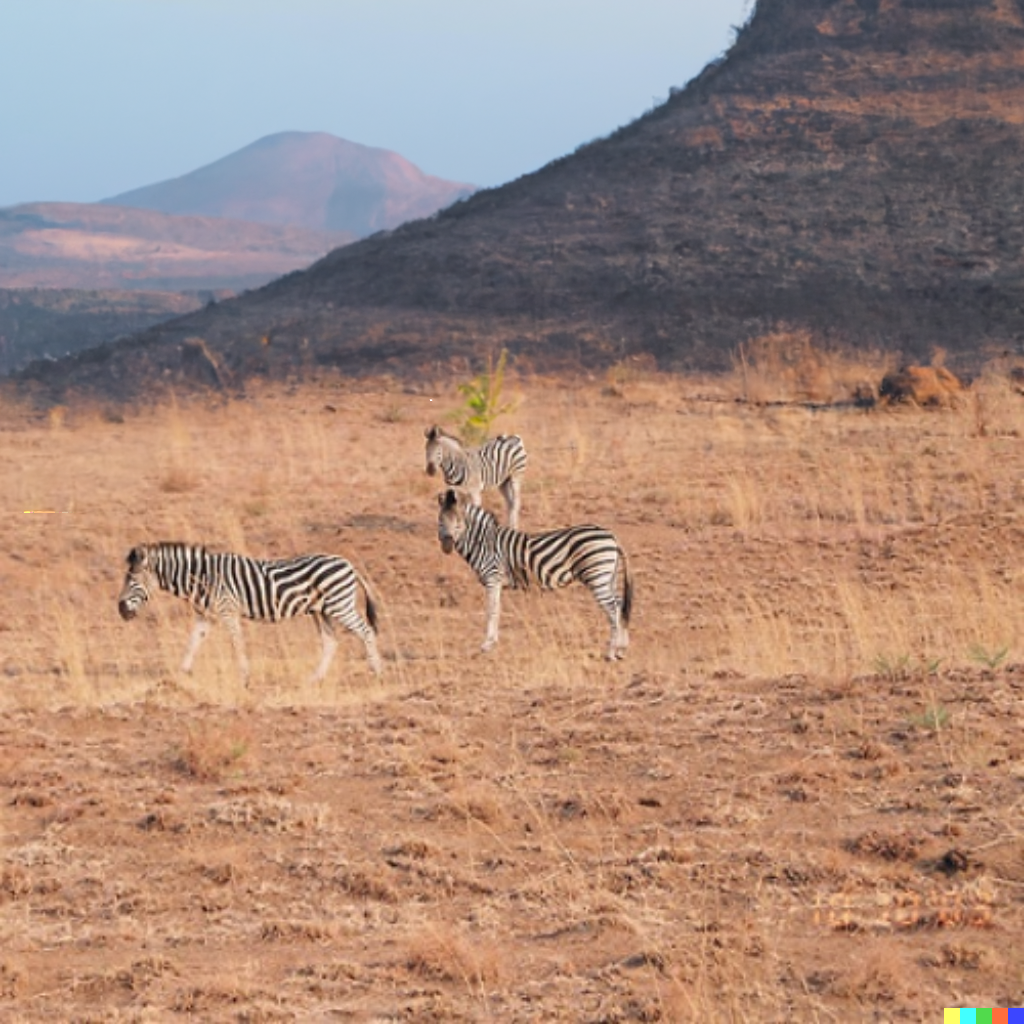

In [12]:
# Display ground-truth edited image
df["target_img"].iloc[0]


### 6. Save to Parquet (images as JPEG bytes)


In [15]:
import io
import pandas as pd
from PIL import Image


def pil_to_jpeg_bytes(img, quality=95):
    """Encode PIL image to JPEG bytes for Parquet compatibility."""
    if isinstance(img, Image.Image):
        buf = io.BytesIO()
        img.convert("RGB").save(buf, format="JPEG", quality=quality)
        return buf.getvalue()
    return None


def jpeg_bytes_to_pil(b):
    """Decode JPEG bytes back to PIL Image."""
    if isinstance(b, (bytes, bytearray)):
        return Image.open(io.BytesIO(b))
    return b


# Save DataFrame to Parquet with images encoded as JPEG bytes
df_to_save = df.copy()
df_to_save["source_img"] = df_to_save["source_img"].apply(pil_to_jpeg_bytes)
df_to_save["mask_img"] = df_to_save["mask_img"].apply(pil_to_jpeg_bytes)
df_to_save["target_img"] = df_to_save["target_img"].apply(pil_to_jpeg_bytes)
df_to_save.to_parquet("magicBrush_data_example.parquet", index=False)


### 7. Verify Parquet round-trip


In [16]:
# Load Parquet file back and restore PIL images
loaded_df = pd.read_parquet("magicBrush_data_example.parquet")
loaded_df["source_img"] = loaded_df["source_img"].apply(jpeg_bytes_to_pil)
loaded_df["mask_img"] = loaded_df["mask_img"].apply(jpeg_bytes_to_pil)
loaded_df["target_img"] = loaded_df["target_img"].apply(jpeg_bytes_to_pil)
loaded_df


,img_id,turn_index,source_img,mask_img,instruction,target_img
0,140513,1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,edit some mountains in the background,<PIL.JpegImagePlugin.JpegImageFile image mode=...
1,140513,2,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,put the zebras next to a river,<PIL.JpegImagePlugin.JpegImageFile image mode=...
2,319096,1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Make the piece of paper hanging on the wall a ...,<PIL.JpegImagePlugin.JpegImageFile image mode=...
3,319096,2,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,put an Easter basket on the desk,<PIL.JpegImagePlugin.JpegImageFile image mode=...
4,393224,1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,What if the man was bald,<PIL.JpegImagePlugin.JpegImageFile image mode=...
5,393224,2,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,what if he had a angry mouth?,<PIL.JpegImagePlugin.JpegImageFile image mode=...
6,122896,1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,Have there be a dolphin jumping out of the water,<PIL.JpegImagePlugin.JpegImageFile image mode=...
7,415314,1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,replace the baseball bat for a laser sword,<PIL.JpegImagePlugin.JpegImageFile image mode=...
8,415314,2,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,switch to a robot wearing armor,<PIL.JpegImagePlugin.JpegImageFile image mode=...
9,75065,1,<PIL.JpegImagePlugin.JpegImageFile image mode=...,<PIL.JpegImagePlugin.JpegImageFile image mode=...,make the cow smile,<PIL.JpegImagePlugin.JpegImageFile image mode=...
